# Recurrent neural networks

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/rnn/rnn-notebook.ipynb)

Companion notebook for the *Recurrent neural networks* slides. Each idea is written first by hand
with NumPy, in small classes shaped like PyTorch's, and then with the PyTorch module that does the same job.

**Data:** a synthetic sine wave with a little noise, cut into windows of $T$ steps; the target is the next value.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error
from torch import nn

RANDOM_STATE = 42
T = 10
HIDDEN = 8
LEARNING_RATE = 0.05
STEPS = 2000
CLIP = 1.0

torch.manual_seed(RANDOM_STATE)
torch.set_default_dtype(torch.float64)
rng = np.random.default_rng(RANDOM_STATE)
series = np.sin(np.arange(400) * 0.2) + 0.05 * rng.normal(size=400)
windows = np.lib.stride_tricks.sliding_window_view(series, T + 1).copy()
X, y = windows[:, :T, None], windows[:, T:]
X_train, X_test, y_train, y_test = X[:300], X[300:], y[:300], y[300:]

## 1. The recurrent cell

$\mathbf{h}_t = \tanh(\mathbf{W}_{hh}\mathbf{h}_{t-1} + \mathbf{W}_{xh}\mathbf{x}_t + \mathbf{b}_h)$, starting at $\mathbf{h}_0 = \mathbf{0}$.
The class uses PyTorch's names: `weight_ih` is $\mathbf{W}_{xh}$, `weight_hh` is $\mathbf{W}_{hh}$, and
PyTorch splits $\mathbf{b}_h$ into two biases, $\mathbf{b}_h$ = `bias_ih` + `bias_hh`.

In [2]:
class RNN:
    """NumPy version of nn.RNN (one layer, tanh, batch_first=True)."""

    def __init__(self, input_size: int, hidden_size: int):
        self.weight_ih = rng.normal(0, 0.5, (hidden_size, input_size))
        self.weight_hh = rng.normal(0, 0.3, (hidden_size, hidden_size))
        self.bias_ih, self.bias_hh = np.zeros(hidden_size), np.zeros(hidden_size)

    def forward(self, x: np.ndarray, h0: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
        """x has shape (batch, T, input_size); returns every state h_1..h_T and the last one."""
        states = [h0]
        for t in range(x.shape[1]):
            states.append(np.tanh(x[:, t] @ self.weight_ih.T + self.bias_ih + states[-1] @ self.weight_hh.T + self.bias_hh))
        outputs = np.stack(states[1:], axis=1)
        return outputs, outputs[:, -1]


def copy_weights(source: RNN, target: nn.RNN) -> None:
    """Copy the NumPy weights into the PyTorch module (its names end in _l0, for layer 0)."""
    with torch.no_grad():
        for name in ["weight_ih", "weight_hh", "bias_ih", "bias_hh"]:
            getattr(target, name + "_l0").copy_(torch.from_numpy(getattr(source, name)))

The slide's example: one state number, $W_{xh} = 1$, $W_{hh} = 0.5$, inputs $1, 0, 1$.

In [3]:
cell = RNN(1, 1)
cell.weight_ih, cell.weight_hh = np.array([[1.0]]), np.array([[0.5]])
inputs = np.array([[[1.0], [0.0], [1.0]]])
outputs, h_n = cell.forward(inputs, np.zeros((1, 1)))
print("states:", outputs.ravel().round(3))

torch_cell = nn.RNN(1, 1, batch_first=True)
copy_weights(cell, torch_cell)
torch_outputs, torch_h_n = torch_cell(torch.from_numpy(inputs), torch.zeros(1, 1, 1))
print("same result:", np.allclose(outputs, torch_outputs.detach().numpy()))

states: [0.762 0.363 0.828]
same result: True


## 2. Backpropagation through time

The network reads a window and predicts the next value from the last state, $\hat{y} = \mathbf{W}_{hy}\mathbf{h}_T + b_y$,
with squared error as the loss. Backpropagation runs back along the states, and the shared weights add up the gradients of all steps.

In [4]:
def bptt(rnn: RNN, x: np.ndarray, outputs: np.ndarray, d_h: np.ndarray) -> list[np.ndarray]:
    """Gradients of weight_ih, weight_hh, bias_ih, bias_hh, given dJ/dh_T, walking back along the states (h_0 = 0)."""
    states = np.concatenate([np.zeros_like(outputs[:, :1]), outputs], axis=1)
    grad_ih, grad_hh, grad_b = 0, 0, 0
    for t in range(x.shape[1], 0, -1):
        d_a = d_h * (1 - states[:, t] ** 2)
        grad_ih, grad_hh, grad_b = grad_ih + d_a.T @ x[:, t - 1], grad_hh + d_a.T @ states[:, t - 1], grad_b + d_a.sum(axis=0)
        d_h = d_a @ rnn.weight_hh
    return [grad_ih, grad_hh, grad_b, grad_b]


rnn = RNN(1, HIDDEN)
head_weight, head_bias = rng.normal(0, 0.5, (1, HIDDEN)), np.zeros(1)


def gradients(X: np.ndarray, y: np.ndarray) -> list[np.ndarray]:
    """Forward pass, then the gradients of every weight: the RNN's four and the head's two (W_hy, b_y)."""
    outputs, h_n = rnn.forward(X, np.zeros((len(X), HIDDEN)))
    d_y = 2 * (h_n @ head_weight.T + head_bias - y) / len(y)
    return bptt(rnn, X, outputs, d_y @ head_weight) + [d_y.T @ h_n, d_y.sum(axis=0)]

PyTorch's autograd finds the same gradients from the forward pass alone: `loss.backward()` fills every `.grad`.

In [5]:
torch_rnn, torch_head = nn.RNN(1, HIDDEN, batch_first=True), nn.Linear(HIDDEN, 1)
copy_weights(rnn, torch_rnn)
with torch.no_grad():
    torch_head.weight.copy_(torch.from_numpy(head_weight))
    torch_head.bias.copy_(torch.from_numpy(head_bias))
torch_params = list(torch_rnn.parameters()) + list(torch_head.parameters())


def torch_predict(X: np.ndarray) -> torch.Tensor:
    _, h_n = torch_rnn(torch.from_numpy(X))  # h_0 defaults to zeros
    return torch_head(h_n[-1])


nn.MSELoss()(torch_predict(X_train), torch.from_numpy(y_train)).backward()
print("same result:", all(np.allclose(g, p.grad.numpy()) for g, p in zip(gradients(X_train, y_train), torch_params)))

same result: True


## 3. Vanishing and exploding gradients

With one state number, $\dfrac{\partial h_T}{\partial h_1} = \prod_{t=2}^{T} w_{hh}\,(1 - h_t^2)$: one factor per step.

In [6]:
def run_scalar(h_1: float, w_hh: float, inputs: np.ndarray) -> np.ndarray:
    states = [h_1]
    for x_t in inputs:
        states.append(np.tanh(w_hh * states[-1] + x_t))
    return np.array(states)


inputs = rng.normal(0, 0.5, 20)
states = run_scalar(0.1, 0.8, inputs)
product = np.prod(0.8 * (1 - states[1:] ** 2))

Autograd follows the same chain of steps backwards and gives the same number.

In [7]:
h_1 = torch.tensor(0.1, requires_grad=True)
h = h_1
for x_t in torch.from_numpy(inputs):
    h = torch.tanh(0.8 * h + x_t)
(autograd,) = torch.autograd.grad(h, h_1)
print(f"dh_T/dh_1 = {product:.2e} | same result:", np.isclose(product, autograd.item()))

dh_T/dh_1 = 4.46e-05 | same result: True


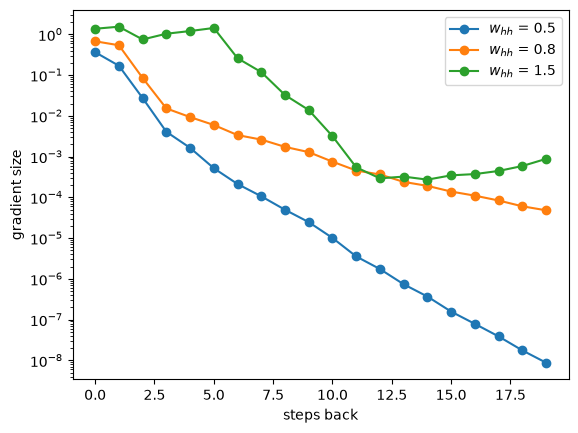

In [8]:
for w_hh in [0.5, 0.8, 1.5]:
    factors = w_hh * (1 - run_scalar(0.0, w_hh, inputs)[1:] ** 2)
    plt.semilogy(np.abs(np.cumprod(factors[::-1])), marker="o", label=f"$w_{{hh}}$ = {w_hh}")
plt.xlabel("steps back")
plt.ylabel("gradient size")
plt.legend()
plt.show()

## 4. Training and forecasting

Gradient descent with the BPTT gradient, $\boldsymbol\theta \leftarrow \boldsymbol\theta - \alpha \nabla J$.
Clipping scales a gradient longer than a threshold back to that length. The NumPy optimizer copies the shape of
`torch.optim.SGD`; PyTorch's `clip_grad_norm_` adds $10^{-6}$ to the length, so we do the same.

In [9]:
class SGD:
    """NumPy version of torch.optim.SGD; step() takes the gradients because NumPy arrays have no .grad."""

    def __init__(self, params: list[np.ndarray], lr: float):
        self.params, self.lr = params, lr

    def step(self, grads: list[np.ndarray]) -> None:
        for param, grad in zip(self.params, grads):
            param -= self.lr * grad


optimizer = SGD([rnn.weight_ih, rnn.weight_hh, rnn.bias_ih, rnn.bias_hh, head_weight, head_bias], lr=LEARNING_RATE)
for _ in range(STEPS):
    grads = gradients(X_train, y_train)
    norm = np.sqrt(sum(np.sum(g ** 2) for g in grads))
    optimizer.step([g * min(1, CLIP / (norm + 1e-6)) for g in grads])

The PyTorch loop, from the same starting weights: `zero_grad`, `backward`, `clip_grad_norm_`, `step`.

In [10]:
torch_optimizer = torch.optim.SGD(torch_params, lr=LEARNING_RATE)
for _ in range(STEPS):
    torch_optimizer.zero_grad()
    nn.MSELoss()(torch_predict(X_train), torch.from_numpy(y_train)).backward()
    nn.utils.clip_grad_norm_(torch_params, CLIP)
    torch_optimizer.step()

print("same weights:", all(np.allclose(p, q.detach().numpy()) for p, q in zip(optimizer.params, torch_params)))

same weights: True


A Ridge regression on the same $T$ past values (lag features) is a reference forecaster.

In [11]:
rnn_mse = mean_squared_error(y_test, torch_predict(X_test).detach().numpy())
ridge_mse = mean_squared_error(y_test, Ridge(alpha=1.0).fit(X_train[:, :, 0], y_train).predict(X_test[:, :, 0]))
last_value_mse = mean_squared_error(y_test, X_test[:, -1])
print(f"test MSE: RNN {rnn_mse:.4f}, Ridge {ridge_mse:.4f}, repeat last value {last_value_mse:.4f}")
print("both beat repeating the last value:", rnn_mse < last_value_mse and ridge_mse < last_value_mse)

test MSE: RNN 0.0042, Ridge 0.0033, repeat last value 0.0251
both beat repeating the last value: True


## 5. The LSTM cell

Gates $\mathbf{f}_t, \mathbf{i}_t, \mathbf{o}_t = \sigma(\mathbf{W}[\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b})$ and candidate $\tilde{\mathbf{c}}_t = \tanh(\mathbf{W}_c[\mathbf{h}_{t-1}, \mathbf{x}_t] + \mathbf{b}_c)$;
then $\mathbf{c}_t = \mathbf{f}_t \odot \mathbf{c}_{t-1} + \mathbf{i}_t \odot \tilde{\mathbf{c}}_t$ and $\mathbf{h}_t = \mathbf{o}_t \odot \tanh(\mathbf{c}_t)$.

Libraries stack the four matrices into one and do a single product per step, split into the part for $\mathbf{x}_t$ (`weight_ih`)
and the part for $\mathbf{h}_{t-1}$ (`weight_hh`). PyTorch's order of the four blocks is $\mathbf{i}, \mathbf{f}, \tilde{\mathbf{c}}, \mathbf{o}$ (it calls $\tilde{\mathbf{c}}$ "g").

In [12]:
def sigmoid(a: np.ndarray) -> np.ndarray:
    return 1 / (1 + np.exp(-a))


class LSTMCell:
    """NumPy version of nn.LSTMCell, gate blocks in PyTorch's order i, f, g, o."""

    def __init__(self, input_size: int, hidden_size: int):
        self.weight_ih = rng.normal(0, 0.5, (4 * hidden_size, input_size))
        self.weight_hh = rng.normal(0, 0.5, (4 * hidden_size, hidden_size))
        self.bias_ih, self.bias_hh = rng.normal(0, 0.1, (2, 4 * hidden_size))

    def forward(self, x: np.ndarray, state: tuple[np.ndarray, np.ndarray]) -> tuple[np.ndarray, np.ndarray]:
        """One step: returns the new (h, c)."""
        h_prev, c_prev = state
        a = x @ self.weight_ih.T + self.bias_ih + h_prev @ self.weight_hh.T + self.bias_hh
        a_i, a_f, a_g, a_o = np.split(a, 4, axis=1)
        c = sigmoid(a_f) * c_prev + sigmoid(a_i) * np.tanh(a_g)
        return sigmoid(a_o) * np.tanh(c), c


lstm = LSTMCell(1, HIDDEN)
x_t, h_prev, c_prev = np.array([[0.7]]), rng.normal(size=(1, HIDDEN)), rng.normal(size=(1, HIDDEN))
h, c = lstm.forward(x_t, (h_prev, c_prev))

torch_lstm = nn.LSTMCell(1, HIDDEN)
with torch.no_grad():
    for name in ["weight_ih", "weight_hh", "bias_ih", "bias_hh"]:
        getattr(torch_lstm, name).copy_(torch.from_numpy(getattr(lstm, name)))
torch_h, torch_c = torch_lstm(torch.from_numpy(x_t), (torch.from_numpy(h_prev), torch.from_numpy(c_prev)))
print("same result:", np.allclose(h, torch_h.detach().numpy()) and np.allclose(c, torch_c.detach().numpy()))

same result: True


## Exercises

1. In section 4, replace `torch.optim.SGD` by `torch.optim.Adam(torch_params, lr=0.01)`. Does the RNN's test error improve?
2. In section 3, find the value of $w_{hh}$ where the gradient stops shrinking over 20 steps.
3. Write one GRU step, $\mathbf{h}_t = (1 - \mathbf{z}_t) \odot \mathbf{h}_{t-1} + \mathbf{z}_t \odot \tilde{\mathbf{h}}_t$, and check that $\mathbf{z}_t = \mathbf{0}$ copies the old state.
   `nn.GRUCell` uses $\mathbf{z}_t$ the other way round: there $\mathbf{z}_t = \mathbf{1}$ copies the old state.